In [16]:
import os
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.utils import to_categorical
from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetV2S
from tensorflow.keras.callbacks import ModelCheckpoint
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.utils.class_weight import compute_class_weight

In [17]:
TRAIN_GROUNDTRUTH_PATH = "/teamspace/studios/this_studio/data/train/ISIC_2019_Training_GroundTruth.csv"
TEST_GROUNDTRUTH_PATH = "/teamspace/studios/this_studio/ham10000/HAM10000_Test_GroundTruth_Updated.csv"
TEST2_GROUNDTRUTH_PATH = "/teamspace/studios/this_studio/data/test/ISIC_2019_Test_GroundTruth.csv"

TRAIN_IMAGE_DIR = "/teamspace/studios/this_studio/data/train/ISIC_2019_Training_Input"
TEST_IMAGE_DIR = "/teamspace/studios/this_studio/ham10000/HAM10000_images_part_12"
TEST2_IMAGE_DIR = "/teamspace/studios/this_studio/data/test/ISIC_2019_Test_Input"

IMG_SIZE = (456, 456)
BATCH_SIZE = 32
EPOCHS = 20
LABELS = ['MEL', 'NV', 'BCC', 'AK', 'BKL', 'DF', 'VASC', 'SCC']

In [18]:
def read_ds(gnd_path):
    df = pd.read_csv(gnd_path)
    return df

def get_image_paths_and_labels(df, image_dir):
    image_paths = [os.path.join(image_dir, row['image'] + '.jpg') for _, row in df.iterrows()]
    labels = df[LABELS].values  # One-hot labels
    return image_paths, labels

train_groundtruth = read_ds(TRAIN_GROUNDTRUTH_PATH)
test_groundtruth = read_ds(TEST_GROUNDTRUTH_PATH)
test_groundtruth_2 = read_ds(TEST2_GROUNDTRUTH_PATH)

train_paths, train_labels = get_image_paths_and_labels(train_groundtruth, TRAIN_IMAGE_DIR)
test_paths, test_labels = get_image_paths_and_labels(test_groundtruth, TEST_IMAGE_DIR)
test_paths_2, test_labels_2 = get_image_paths_and_labels(test_groundtruth_2, TEST2_IMAGE_DIR)

In [19]:
from sklearn.model_selection import train_test_split

train_paths, temp_paths, train_labels, temp_labels = train_test_split(
    train_paths, train_labels, test_size=0.2, stratify=train_labels, random_state=42
)

val_paths, test_paths, val_labels, test_labels = train_test_split(
    temp_paths, temp_labels, test_size=0.5, stratify=temp_labels, random_state=42
)

In [20]:
def load_image(file_path, label):
    img = tf.io.read_file(file_path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, IMG_SIZE)
    img = tf.keras.applications.efficientnet.preprocess_input(img)
    return img, label

def preprocess_and_augment(file_path, label):
    img, label = load_image(file_path, label)
    img = tf.image.random_flip_left_right(img)
    img = tf.image.random_flip_up_down(img)
    img = tf.image.random_brightness(img, max_delta=0.2)
    img = tf.image.random_contrast(img, lower=0.8, upper=1.2)
    return img, label

train_dataset = tf.data.Dataset.from_tensor_slices((train_paths, train_labels))
train_dataset = train_dataset.map(preprocess_and_augment).shuffle(512).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

val_dataset = tf.data.Dataset.from_tensor_slices((val_paths, val_labels))
val_dataset = val_dataset.map(load_image).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

test_dataset = tf.data.Dataset.from_tensor_slices((test_paths, test_labels))
test_dataset = test_dataset.map(load_image).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


In [ ]:
def build_model():
    base_model = EfficientNetV2S(weights="imagenet", include_top=False, input_shape=(*IMG_SIZE, 3))
    

    base_model.trainable = True
    for layer in base_model.layers[:int(len(base_model.layers) * 0.7)]:
        layer.trainable = False 

    inputs = tf.keras.Input(shape=(*IMG_SIZE, 3))
    x = base_model(inputs, training=False)

    x = layers.GlobalAveragePooling2D()(x) 


    x = layers.Dense(2048, activation="mish")(x)  
    x = layers.Dropout(0.4)(x)  
    x = layers.LayerNormalization()(x)  

    x = layers.Dense(1024, activation="mish")(x)
    x = layers.Dropout(0.3)(x)

    x = layers.Dense(512, activation="mish")(x)
    x = layers.Dropout(0.2)(x)

    se = layers.Lambda(lambda t: tf.expand_dims(t, axis=-1))(x) 
    se = layers.GlobalAveragePooling1D()(se)
    se = layers.Dense(64, activation="relu")(se)
    se = layers.Dense(512, activation="sigmoid")(se)
    x = layers.Multiply()([x, se])

    outputs = layers.Dense(len(LABELS), activation="softmax")(x)
    model = models.Model(inputs, outputs)

    optimizer = tf.keras.optimizers.Adam(learning_rate=1e-4)

    model.compile(
        optimizer=optimizer, 
        loss="categorical_crossentropy",  
        metrics=[
            "accuracy",
            tf.keras.metrics.AUC(name="auc"),
            tf.keras.metrics.Precision(name="precision"), 
            tf.keras.metrics.Recall(name="recall")
        ]
)


    return model

model = build_model()


In [22]:
train_labels_argmax = np.argmax(train_labels, axis=1)
class_weights = compute_class_weight(class_weight="balanced", classes=np.arange(len(LABELS)), y=train_labels_argmax)
class_weights_dict = {i: weight for i, weight in enumerate(class_weights)}

In [23]:
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 456, 456,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ efficientnetv2-s    │ (None, 15, 15,    │ 20,331,360 │ input_layer_3[0]… │
│ (Functional)        │ 1280)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 1280)      │          0 │ efficientnetv2-s… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_6 (Dense)     │ (None, 2048)      │  2,623,488 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 2048)      │          0 │ dense_6[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 2048)      │      4,096 │ dropout_3[0][0]   │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_7 (Dense)     │ (None, 1024)      │  2,098,176 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_4 (Dropout) │ (None, 1024)      │          0 │ dense_7[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_8 (Dense)     │ (None, 512)       │    524,800 │ dropout_4[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_5 (Dropout) │ (None, 512)       │          0 │ dense_8[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lambda_1 (Lambda)   │ (None, 512, 1)    │          0 │ dropout_5[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 1)         │          0 │ lambda_1[0][0]    │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_9 (Dense)     │ (None, 64)        │        128 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_10 (Dense)    │ (None, 512)       │     33,280 │ dense_9[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply_1          │ (None, 512)       │          0 │ dropout_5[0][0],  │
│ (Multiply)          │                   │            │ dense_10[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_11 (Dense)    │ (None, 8)         │      4,104 │ multiply_1[0][0]  │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 25,619,432 (97.73 MB)

 Trainable params: 15,669,512 (59.77 MB)

 Non-trainable params: 9,949,920 (37.96 MB)

In [25]:
checkpoint = ModelCheckpoint("efficientnet-v2-m-onehot-deep-split_baserun.keras", monitor="val_accuracy", save_best_only=True, mode="max", verbose=1)
lr_scheduler = tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", 
                                                    factor=0.5, 
                                                    patience=3, 
                                                    min_lr=1e-6, 
                                                    verbose=1)
                                                    
history = model.fit(train_dataset, validation_data=val_dataset, epochs=EPOCHS, callbacks=[checkpoint, lr_scheduler],
                    class_weight=class_weights_dict)

Epoch 1/20


633/634 ━━━━━━━━━━━━━━━━━━━━ 0s 336ms/step - accuracy: 0.4586 - auc: 0.8453 - loss: 1.3991 - precision: 0.6027 - recall: 0.2760

2025-03-17 12:30:24.026557: I external/local_xla/xla/stream_executor/cuda/cuda_asm_compiler.cc:397] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_31732', 208 bytes spill stores, 332 bytes spill loads



634/634 ━━━━━━━━━━━━━━━━━━━━ 0s 407ms/step - accuracy: 0.4587 - auc: 0.8453 - loss: 1.3991 - precision: 0.6028 - recall: 0.2761
Epoch 1: val_accuracy improved from -inf to 0.58389, saving model to efficientnet-v2-m-onehot-deep-split_baserun.keras
634/634 ━━━━━━━━━━━━━━━━━━━━ 300s 464ms/step - accuracy: 0.4587 - auc: 0.8453 - loss: 1.3990 - precision: 0.6028 - recall: 0.2762 - val_accuracy: 0.5839 - val_auc: 0.9139 - val_loss: 1.1325 - val_precision: 0.6410 - val_recall: 0.5124 - learning_rate: 1.0000e-04
Epoch 2/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 0s 342ms/step - accuracy: 0.5712 - auc: 0.9074 - loss: 0.9981 - precision: 0.6569 - recall: 0.4648
Epoch 2: val_accuracy improved from 0.58389 to 0.64114, saving model to efficientnet-v2-m-onehot-deep-split_baserun.keras
634/634 ━━━━━━━━━━━━━━━━━━━━ 238s 366ms/step - accuracy: 0.5713 - auc: 0.9074 - loss: 0.9981 - precision: 0.6569 - recall: 0.4649 - val_accuracy: 0.6411 - val_auc: 0.9322 - val_loss: 1.0145 - val_precision: 0.6888 - val_recall: 0

In [27]:
checkpoint = ModelCheckpoint("efficientnet-v2-m-onehot-deep-split_baserun_2.keras", monitor="val_accuracy", save_best_only=True, mode="max", verbose=1)
lr_scheduler = tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", 
                                                    factor=0.5, 
                                                    patience=3, 
                                                    min_lr=1e-6, 
                                                    verbose=1)
                                                    
history2 = model.fit(train_dataset, validation_data=val_dataset, epochs=EPOCHS, callbacks=[checkpoint, lr_scheduler],
                    class_weight=class_weights_dict)

Epoch 1/20


634/634 ━━━━━━━━━━━━━━━━━━━━ 0s 337ms/step - accuracy: 0.9015 - auc: 0.9940 - loss: 0.1371 - precision: 0.9068 - recall: 0.8953
Epoch 1: val_accuracy improved from -inf to 0.82432, saving model to efficientnet-v2-m-onehot-deep-split_baserun_2.keras
634/634 ━━━━━━━━━━━━━━━━━━━━ 235s 361ms/step - accuracy: 0.9015 - auc: 0.9940 - loss: 0.1371 - precision: 0.9068 - recall: 0.8953 - val_accuracy: 0.8243 - val_auc: 0.9691 - val_loss: 0.6595 - val_precision: 0.8308 - val_recall: 0.8220 - learning_rate: 2.5000e-05
Epoch 2/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 0s 332ms/step - accuracy: 0.9080 - auc: 0.9940 - loss: 0.1328 - precision: 0.9144 - recall: 0.9013
Epoch 2: val_accuracy improved from 0.82432 to 0.82906, saving model to efficientnet-v2-m-onehot-deep-split_baserun_2.keras
634/634 ━━━━━━━━━━━━━━━━━━━━ 231s 356ms/step - accuracy: 0.9080 - auc: 0.9940 - loss: 0.1328 - precision: 0.9144 - recall: 0.9013 - val_accuracy: 0.8291 - val_auc: 0.9687 - val_loss: 0.6575 - val_precision: 0.8336 - val_recal

In [28]:
checkpoint = ModelCheckpoint("efficientnet-v2-m-onehot-deep-split_baserun_2.keras", monitor="val_accuracy", save_best_only=True, mode="max", verbose=1)
lr_scheduler = tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", 
                                                    factor=0.5, 
                                                    patience=3, 
                                                    min_lr=1e-6, 
                                                    verbose=1)
                                                    
history3 = model.fit(train_dataset, validation_data=val_dataset, epochs=EPOCHS, callbacks=[checkpoint, lr_scheduler],
                    class_weight=class_weights_dict)

Epoch 1/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 0s 334ms/step - accuracy: 0.9421 - auc: 0.9978 - loss: 0.0734 - precision: 0.9478 - recall: 0.9387
Epoch 1: val_accuracy improved from -inf to 0.83853, saving model to efficientnet-v2-m-onehot-deep-split_baserun_2.keras
634/634 ━━━━━━━━━━━━━━━━━━━━ 233s 359ms/step - accuracy: 0.9421 - auc: 0.9978 - loss: 0.0734 - precision: 0.9478 - recall: 0.9387 - val_accuracy: 0.8385 - val_auc: 0.9683 - val_loss: 0.6954 - val_precision: 0.8415 - val_recall: 0.8362 - learning_rate: 1.0000e-06
Epoch 2/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 0s 333ms/step - accuracy: 0.9399 - auc: 0.9973 - loss: 0.0809 - precision: 0.9441 - recall: 0.9372
Epoch 2: val_accuracy improved from 0.83853 to 0.84366, saving model to efficientnet-v2-m-onehot-deep-split_baserun_2.keras
634/634 ━━━━━━━━━━━━━━━━━━━━ 232s 358ms/step - accuracy: 0.9399 - auc: 0.9973 - loss: 0.0809 - precision: 0.9441 - recall: 0.9372 - val_accuracy: 0.8437 - val_auc: 0.9700 - val_loss: 0.6858 - val_precision: 0.8460 

58/80 ━━━━━━━━━━━━━━━━━━━━ 3s 166ms/step - accuracy: 0.8440 - auc: 0.9662 - loss: 0.7485 - precision: 0.8475 - recall: 0.8404

80/80 ━━━━━━━━━━━━━━━━━━━━ 23s 290ms/step - accuracy: 0.8459 - auc: 0.9671 - loss: 0.7300 - precision: 0.8493 - recall: 0.8426


2025-03-17 16:26:08.087515: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


80/80 ━━━━━━━━━━━━━━━━━━━━ 31s 278ms/step
              precision    recall  f1-score   support

         MEL       0.74      0.78      0.76       452
          NV       0.92      0.89      0.90      1288
         BCC       0.87      0.93      0.90       333
          AK       0.69      0.76      0.72        86
         BKL       0.79      0.76      0.77       263
          DF       0.75      0.75      0.75        24
        VASC       0.85      0.88      0.86        25
         SCC       0.73      0.70      0.72        63

    accuracy                           0.85      2534
   macro avg       0.79      0.81      0.80      2534
weighted avg       0.85      0.85      0.85      2534



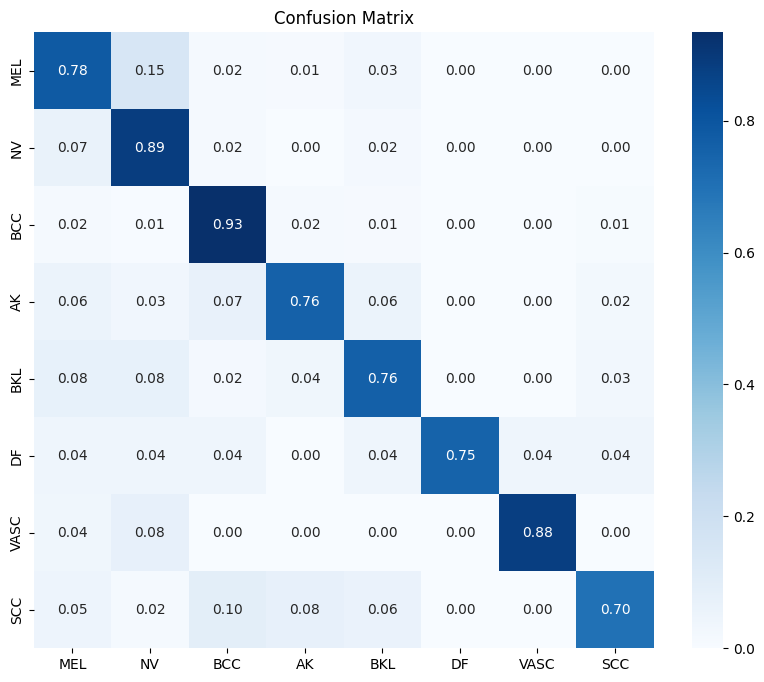

In [29]:
result = model.evaluate(test_dataset)
y_true = np.argmax(np.concatenate([y.numpy() for _, y in test_dataset]), axis=1)
y_pred = np.argmax(model.predict(test_dataset), axis=1)

print(classification_report(y_true, y_pred, target_names=LABELS))

conf_matrix = confusion_matrix(y_true, y_pred, normalize="true")
plt.figure(figsize=(10, 8))
sns.heatmap(conf_matrix, annot=True, cmap="Blues", fmt=".2f", xticklabels=LABELS, yticklabels=LABELS)
plt.title("Confusion Matrix")
plt.show()

# Fine-tuning

In [18]:
tf.compat.v1.enable_eager_execution()
model = tf.keras.models.load_model('/teamspace/studios/this_studio/models/weights/efficientnet-v2-m-onehot_baserun.keras')

/Users/mac/Library/Caches/pypoetry/virtualenvs/diploma-JhBIondL-py3.11/lib/python3.11/site-packages/keras/src/saving/saving_lib.py:757: UserWarning: Skipping variable loading for optimizer 'adam', because it has 1308 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


In [15]:
model.evaluate(test_dataset_2)

258/258 ━━━━━━━━━━━━━━━━━━━━ 580s 2s/step - accuracy: 0.5873 - loss: 0.8531 - precision: 0.6827 - recall: 0.5625


[0.8416513204574585,
 0.4922311305999756,
 0.5843790769577026,
 0.5039573311805725]

In [20]:
for layer in model.layers:
     if layer.name == 'efficientnetv2-m':
         layer.trainable = True
         for l in layer.layers[:-200]:
              l.trainable = False
         for l in layer.layers[-200:]:
              l.trainable = True
     if layer.name == 'batch_normalization_1':
         layer.trainable = False
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 456, 456, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetv2-m (Functional)   │ (None, 15, 15, 1280)   │    53,150,388 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1024)           │     1,311,744 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 1024)           │         4,096 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 8)              │         8,200 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 162,835,126 (621.17 MB)

 Trainable params: 31,530,196 (120.28 MB)

 Non-trainable params: 22,944,232 (87.53 MB)

 Optimizer params: 108,360,698 (413.36 MB)

In [21]:
checkpoint = ModelCheckpoint("efficientnet-v2-m-onehot_finetuning.keras", monitor="val_accuracy", save_best_only=True, mode="max", verbose=1)
history = model.fit(train_dataset, validation_data=test_dataset, epochs=EPOCHS, callbacks=[checkpoint],
                    class_weight=class_weights_dict)

Epoch 1/20


792/792 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.6119 - loss: 0.9054 - precision: 0.6894 - recall: 0.5100
Epoch 1: val_accuracy improved from -inf to 0.56555, saving model to efficientnet-v2-m-onehot_finetuning.keras
792/792 ━━━━━━━━━━━━━━━━━━━━ 2619s 3s/step - accuracy: 0.6118 - loss: 0.9058 - precision: 0.6894 - recall: 0.5099 - val_accuracy: 0.5656 - val_loss: 1.2173 - val_precision: 0.6631 - val_recall: 0.4442
Epoch 2/20
792/792 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.6558 - loss: 0.6761 - precision: 0.7386 - recall: 0.5603
Epoch 2: val_accuracy improved from 0.56555 to 0.62566, saving model to efficientnet-v2-m-onehot_finetuning.keras
792/792 ━━━━━━━━━━━━━━━━━━━━ 2177s 3s/step - accuracy: 0.6558 - loss: 0.6764 - precision: 0.7386 - recall: 0.5603 - val_accuracy: 0.6257 - val_loss: 1.0137 - val_precision: 0.6772 - val_recall: 0.5494
Epoch 3/20
792/792 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.6923 - loss: 0.5476 - precision: 0.7503 - recall: 0.6250
Epoch 3: val_accur

KeyboardInterrupt: 

In [ ]:
checkpoint = ModelCheckpoint("efficientnet-v2-m-onehot_finetuning.keras", monitor="val_accuracy", save_best_only=True, mode="max", verbose=1)
history = model.fit(train_dataset, validation_data=test_dataset_2, epochs=EPOCHS, callbacks=[checkpoint],
                    class_weight=class_weights_dict)

Epoch 1/20
792/792 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.7569 - loss: 0.3798 - precision: 0.7922 - recall: 0.7203
Epoch 1: val_accuracy improved from -inf to 0.50522, saving model to efficientnet-v2-m-onehot_finetuning.keras
792/792 ━━━━━━━━━━━━━━━━━━━━ 2074s 3s/step - accuracy: 0.7570 - loss: 0.3799 - precision: 0.7922 - recall: 0.7203 - val_accuracy: 0.5052 - val_loss: 0.9712 - val_precision: 0.5086 - val_recall: 0.6099
Epoch 2/20
792/792 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.7700 - loss: 0.3524 - precision: 0.7983 - recall: 0.7368
Epoch 2: val_accuracy did not improve from 0.50522
792/792 ━━━━━━━━━━━━━━━━━━━━ 2025s 3s/step - accuracy: 0.7700 - loss: 0.3524 - precision: 0.7984 - recall: 0.7369 - val_accuracy: 0.4942 - val_loss: 1.1084 - val_precision: 0.4868 - val_recall: 0.5870
Epoch 3/20
792/792 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.7780 - loss: 0.3390 - precision: 0.8038 - recall: 0.7458
Epoch 3: val_accuracy improved from 0.50522 to 0.51238, saving model t

In [40]:
model.save('efficientnet-v2-m-onehot_baserun.keras')